# Why is the variance explained by MEFISTO is low on the embryos?

## What the Data Looks Like
MEFISTO and plain MOFA fit to the two E8.0 embryos of the SEU-3D digital embryo.

The setup is 2,500 Stereo-seq cell bins per embryo, 2,000 highly variable genes, 12 factors, the embryos as groups and (x, y, z) as covariates.
Total variance explained came out at a few percent, which got questioned at the lab meeting. This notebook works through why.

Sections: 1 the numbers; 2 why they are low; 3 a better score for this data; 4 sanity checks (the MEFISTO paper's own Visium
example, re-run with this code); 5 MOFA vs MEFISTO; 6 what it means for our data.

The notebook just loads saved models. To regenerate them (details in `README.md`):
```
python prep.py 2500
OPTFREQ=25 python fit.py data/e8_joint_2500per.h5ad models/mefisto_e8_2500per_K12.hdf5 12 300 0.1
python fit.py data/e8_joint_2500per.h5ad models/mofa_e8_2500per_K12.hdf5 12 300 0.1 nogp
python paper_recipe.py prep && python paper_recipe.py fit 4 && python paper_recipe.py fit 12 && python paper_recipe.py fit 12 nogp
```


In [1]:
import numpy as np, pandas as pd, anndata as ad
from IPython.display import Image, display
import analysis as A, compare
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', None)

MODELS = {   # name: (saved model, the matrix it was fitted to)
    'MEFISTO (presented)':          ('models/mefisto_e8_2500per_K12.hdf5', 'data/e8_joint_2500per.h5ad'),
    'MOFA (presented)':             ('models/mofa_e8_2500per_K12.hdf5',    'data/e8_joint_2500per.h5ad'),
    'MEFISTO, paper recipe, K=4':   ('models/paper_e8_vst_K4.hdf5',        'data/e8_joint_2500per_vst.h5ad'),
    'MEFISTO, paper recipe, K=12':  ('models/paper_e8_vst_K12.hdf5',       'data/e8_joint_2500per_vst.h5ad'),
    'MOFA, paper genes, K=12':      ('models/paper_e8_vst_K12_mofa.hdf5',  'data/e8_joint_2500per_vst.h5ad'),
}
M = {k: A.load_model(p) for k, (p, _) in MODELS.items()}

## 1. The numbers

mofapy2 reports R2 per embryo as 1 - SS_res / SS_tot, where every gene is centred within the embryo and the reconstruction is Z W^T using all factors. "Presented" is the fit I showed at the meeting. "Paper recipe" uses the same cells and counts but with the MEFISTO paper's own Visium settings (genes chosen by Seurat's vst method on counts, 1,000 inducing points, the paper's convergence settings)- see section 4.


In [2]:
r2 = pd.DataFrame({k: m['r2_total'] for k, m in M.items()}).T.round(2)
r2.columns = ['R2 rep1 (%)', 'R2 rep2 (%)']
r2['active factors'] = [len(A.active_factors(m)) for m in M.values()]
r2

,R2 rep1 (%),R2 rep2 (%),active factors
MEFISTO (presented),2.73,4.01,7
MOFA (presented),6.90,9.05,12
"MEFISTO, paper recipe, K=4",3.74,6.49,4
"MEFISTO, paper recipe, K=12",4.51,7.17,8
"MOFA, paper genes, K=12",9.24,13.20,12


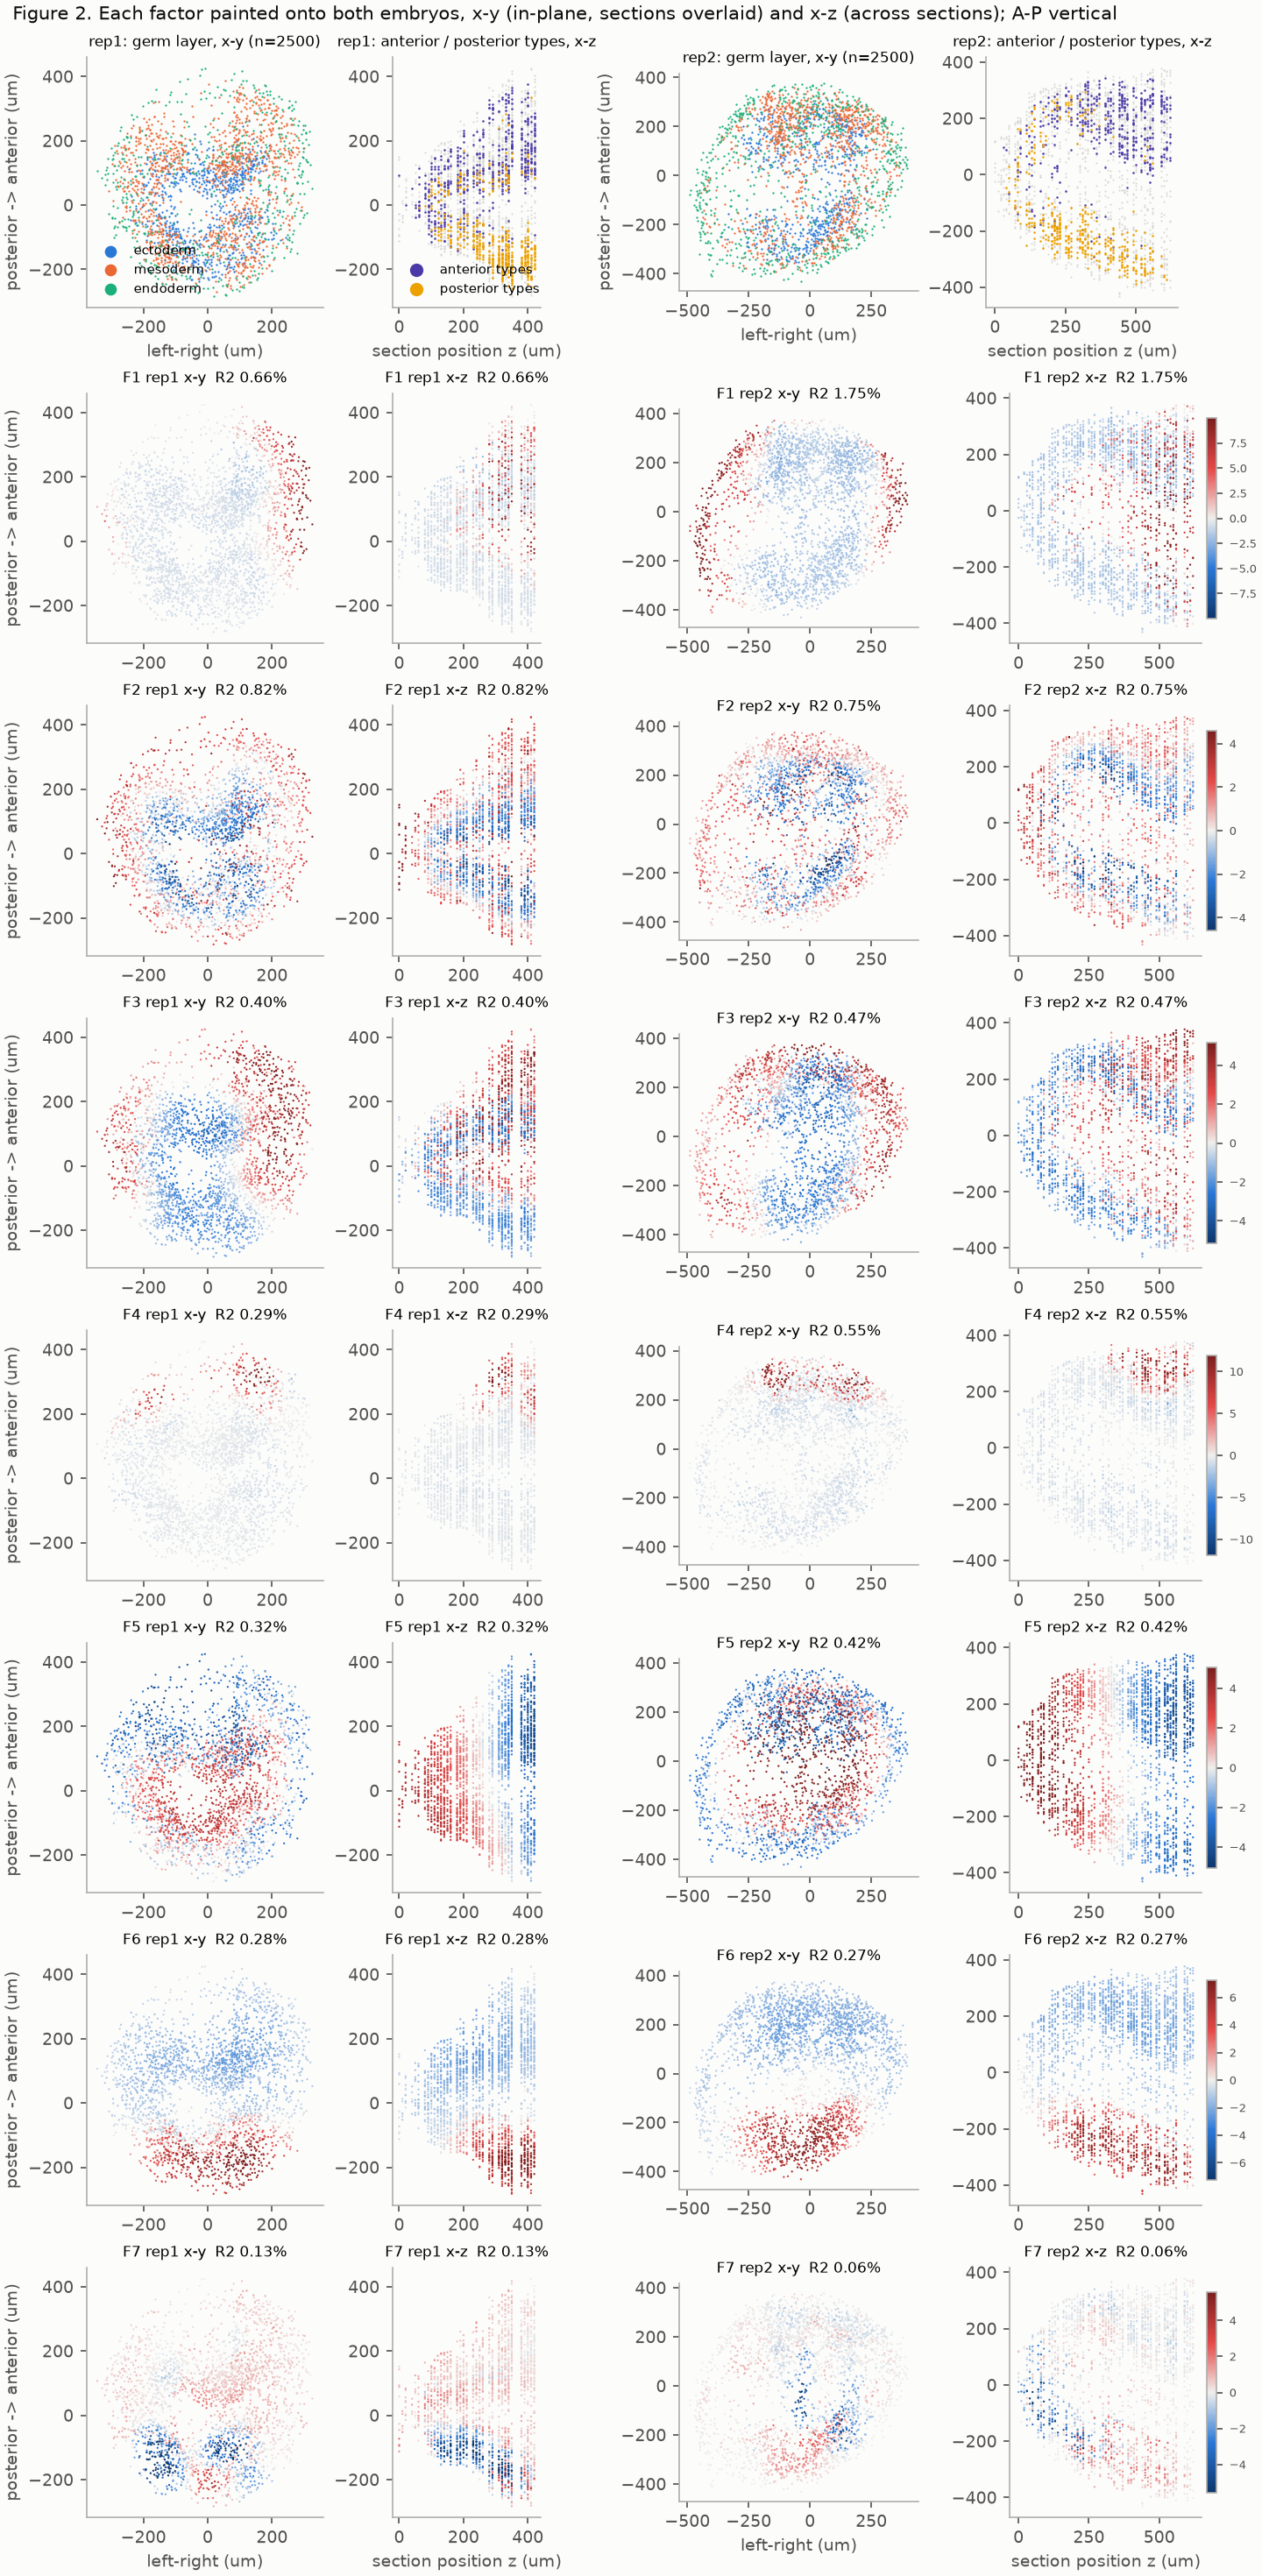

In [3]:
display(Image('figures/fig2_factors_in_space.png'))   # the presented factors, for reference

## 2. Why it is low

Each bin holds about 1,200 counts over about 16,000 genes, so a typical gene is seen 0.07 times per bin. At that depth most of the per-entry variance is just sampling noise, which no model scored per entry can explain.

Two numbers from the data give a sense of how much is left for any model:

- the share of the variance that lies **between cell types**, i.e. what a model that knew every bin's published label would explain by predicting each bin with its type's mean profile;
- the **12-PC ceiling**: the best any 12-factor linear reconstruction can do on this matrix (Eckart-Young), computed per embryo on the same centred matrix mofapy2 scores against.

> **[fill in: the Poisson argument. Variance of a count equals its mean; between-type signal scales with depth squared, noise
> with depth, so signal-to-noise scales with depth. Why 0.07 counts per gene puts almost every gene in the noise-dominated regime.]**


In [4]:
depth = {}
for g, f in [('E8.0_rep1', 'data/GSM9046247_Embryo_E8.0_stereo_rep1.h5ad'), ('E8.0_rep2', 'data/GSM9046248_Embryo_E8.0_stereo_rep2.h5ad')]:
    o = ad.read_h5ad(f, backed='r').obs
    depth[g] = dict(bins=len(o), median_counts_per_bin=int(o.nCount_SCT.median()), median_genes_per_bin=int(o.nFeature_SCT.median()))
pd.DataFrame(depth).T

,bins,median_counts_per_bin,median_genes_per_bin
E8.0_rep1,11048,1181,633
E8.0_rep2,27266,1327,658


In [5]:
ceiling = pd.read_csv('pca_ceiling.csv').rename(columns={'zeros': 'zeros (%)', 'pc4': '4-PC ceiling (%)', 'pc12': '12-PC ceiling (%)'})
ceiling

,genes,embryo,zeros (%),4-PC ceiling (%),12-PC ceiling (%)
0,dispersion (presented),E8.0_rep1,96.3,5.55,10.38
1,dispersion (presented),E8.0_rep2,96.0,7.44,12.22
2,vst (paper),E8.0_rep1,97.9,7.98,14.26
3,vst (paper),E8.0_rep2,97.7,11.38,18.05


## 3. A better score for this data: variance explained on cell-type averages

`analysis.pseudobulk_r2`: per embryo, I average the centred data and the reconstruction Z W^T over all bins of each published cell type (only types with at least 25 bins), then score R2 on those type-mean profiles, with each type counted once. As a check the per-cell R2 is recomputed the same way (it matches mofapy2's number). `between_type_share` is the between-type share of per-cell variance from section 2.

> **[fill in: why averaging n bins divides the sampling variance by n but leaves the type-mean signal alone, so the denominator
> ends up mostly biology. Caveat: the between-type structure is only 3.5 to 8% of the per-cell variance, so "78%" is
> 78% of that slice.]**


In [6]:
pb = pd.concat({k: A.pseudobulk_r2(m, MODELS[k][1]) for k, m in M.items()}, names=['model']).reset_index(level=1, drop=True)
pb

,embryo,n_types,cells_in_types,r2_cell,r2_pseudobulk,between_type_share
model,,,,,,
MEFISTO (presented),E8.0_rep1,12,2393,2.73,54.83,3.46
MEFISTO (presented),E8.0_rep2,14,2414,4.01,50.85,5.15
MOFA (presented),E8.0_rep1,12,2393,6.90,78.35,3.46
MOFA (presented),E8.0_rep2,14,2414,9.05,74.65,5.15
"MEFISTO, paper recipe, K=4",E8.0_rep1,12,2393,3.74,57.44,5.05
"MEFISTO, paper recipe, K=4",E8.0_rep2,14,2414,6.49,57.49,7.87
"MEFISTO, paper recipe, K=12",E8.0_rep1,12,2393,4.51,60.84,5.05
"MEFISTO, paper recipe, K=12",E8.0_rep2,14,2414,7.17,59.41,7.87
"MOFA, paper genes, K=12",E8.0_rep1,12,2393,9.24,81.05,5.05


## 4. Sanity checks

### 4a. The MEFISTO paper's own Visium example, re-run with this code

Velten et al. 2022, Extended Data Fig. 9: 10x Visium mouse brain, anterior section 1 (2,696 spots, 4 factors). The paper's
trained model is on figshare (13233860) and the input matrix is stored inside it. The rows below are from `sanity/tables/all_models.csv`
(scripts in `sanity/scripts/`):

- `official_exact`: the paper's matrix with the paper's settings, just refitted here.
- `official_mine`: the 10x counts through a Seurat-style preprocessing (vst genes) with the paper's settings.
- `ours`, `abl_K4`: `prep.py` + `fit.py` on the 10x counts at K = 12 and K = 4.
- `abl_all_official`: our preprocessing, but every fit setting is the paper's.
- `mofa_official`, `mofa_ours`: plain MOFA.

"best match" is the absolute correlation of each paper factor with its closest factor in the fit, over the common spots.


In [7]:
S = pd.read_csv('sanity/tables/all_models.csv').set_index('name')
rows = ['paper (ST_model.hdf5, figshare)', 'official_exact', 'official_mine', 'ours', 'abl_K4', 'abl_all_official', 'mofa_official', 'mofa_ours']
S.loc[rows, ['K', 'n_active', 'r2_total', 'match_official']].rename(columns={'n_active': 'active', 'r2_total': 'R2 (%)', 'match_official': 'best match to paper factors'})

,K,active,R2 (%),best match to paper factors
name,,,,
"paper (ST_model.hdf5, figshare)",NaN,4,33.34,NaN
official_exact,4.0,4,33.43,"{'F1': ('F1', 0.99), 'F2': ('F2', 0.99), 'F3': ('F3', 1.0), 'F4': ('F4', 1.0)}"
official_mine,4.0,4,35.19,"{'F1': ('F1', 0.93), 'F2': ('F2', 0.98), 'F3': ('F3', 0.99), 'F4': ('F4', 0.64)}"
ours,12.0,9,32.20,"{'F1': ('F2', 0.73), 'F2': ('F1', 0.96), 'F3': ('F3', 0.99), 'F4': ('F4', 0.84)}"
abl_K4,4.0,4,26.62,"{'F1': ('F2', 0.81), 'F2': ('F1', 0.94), 'F3': ('F3', 0.95), 'F4': ('F4', 0.86)}"
abl_all_official,4.0,4,29.39,"{'F1': ('F1', 0.81), 'F2': ('F2', 0.94), 'F3': ('F3', 0.97), 'F4': ('F4', 0.81)}"
mofa_official,4.0,4,35.42,"{'F1': ('F1', 0.94), 'F2': ('F2', 0.91), 'F3': ('F3', 0.94), 'F4': ('F4', 0.96)}"
mofa_ours,12.0,9,37.56,"{'F1': ('F1', 0.76), 'F2': ('F2', 0.97), 'F3': ('F3', 0.97), 'F4': ('F8', 0.94)}"


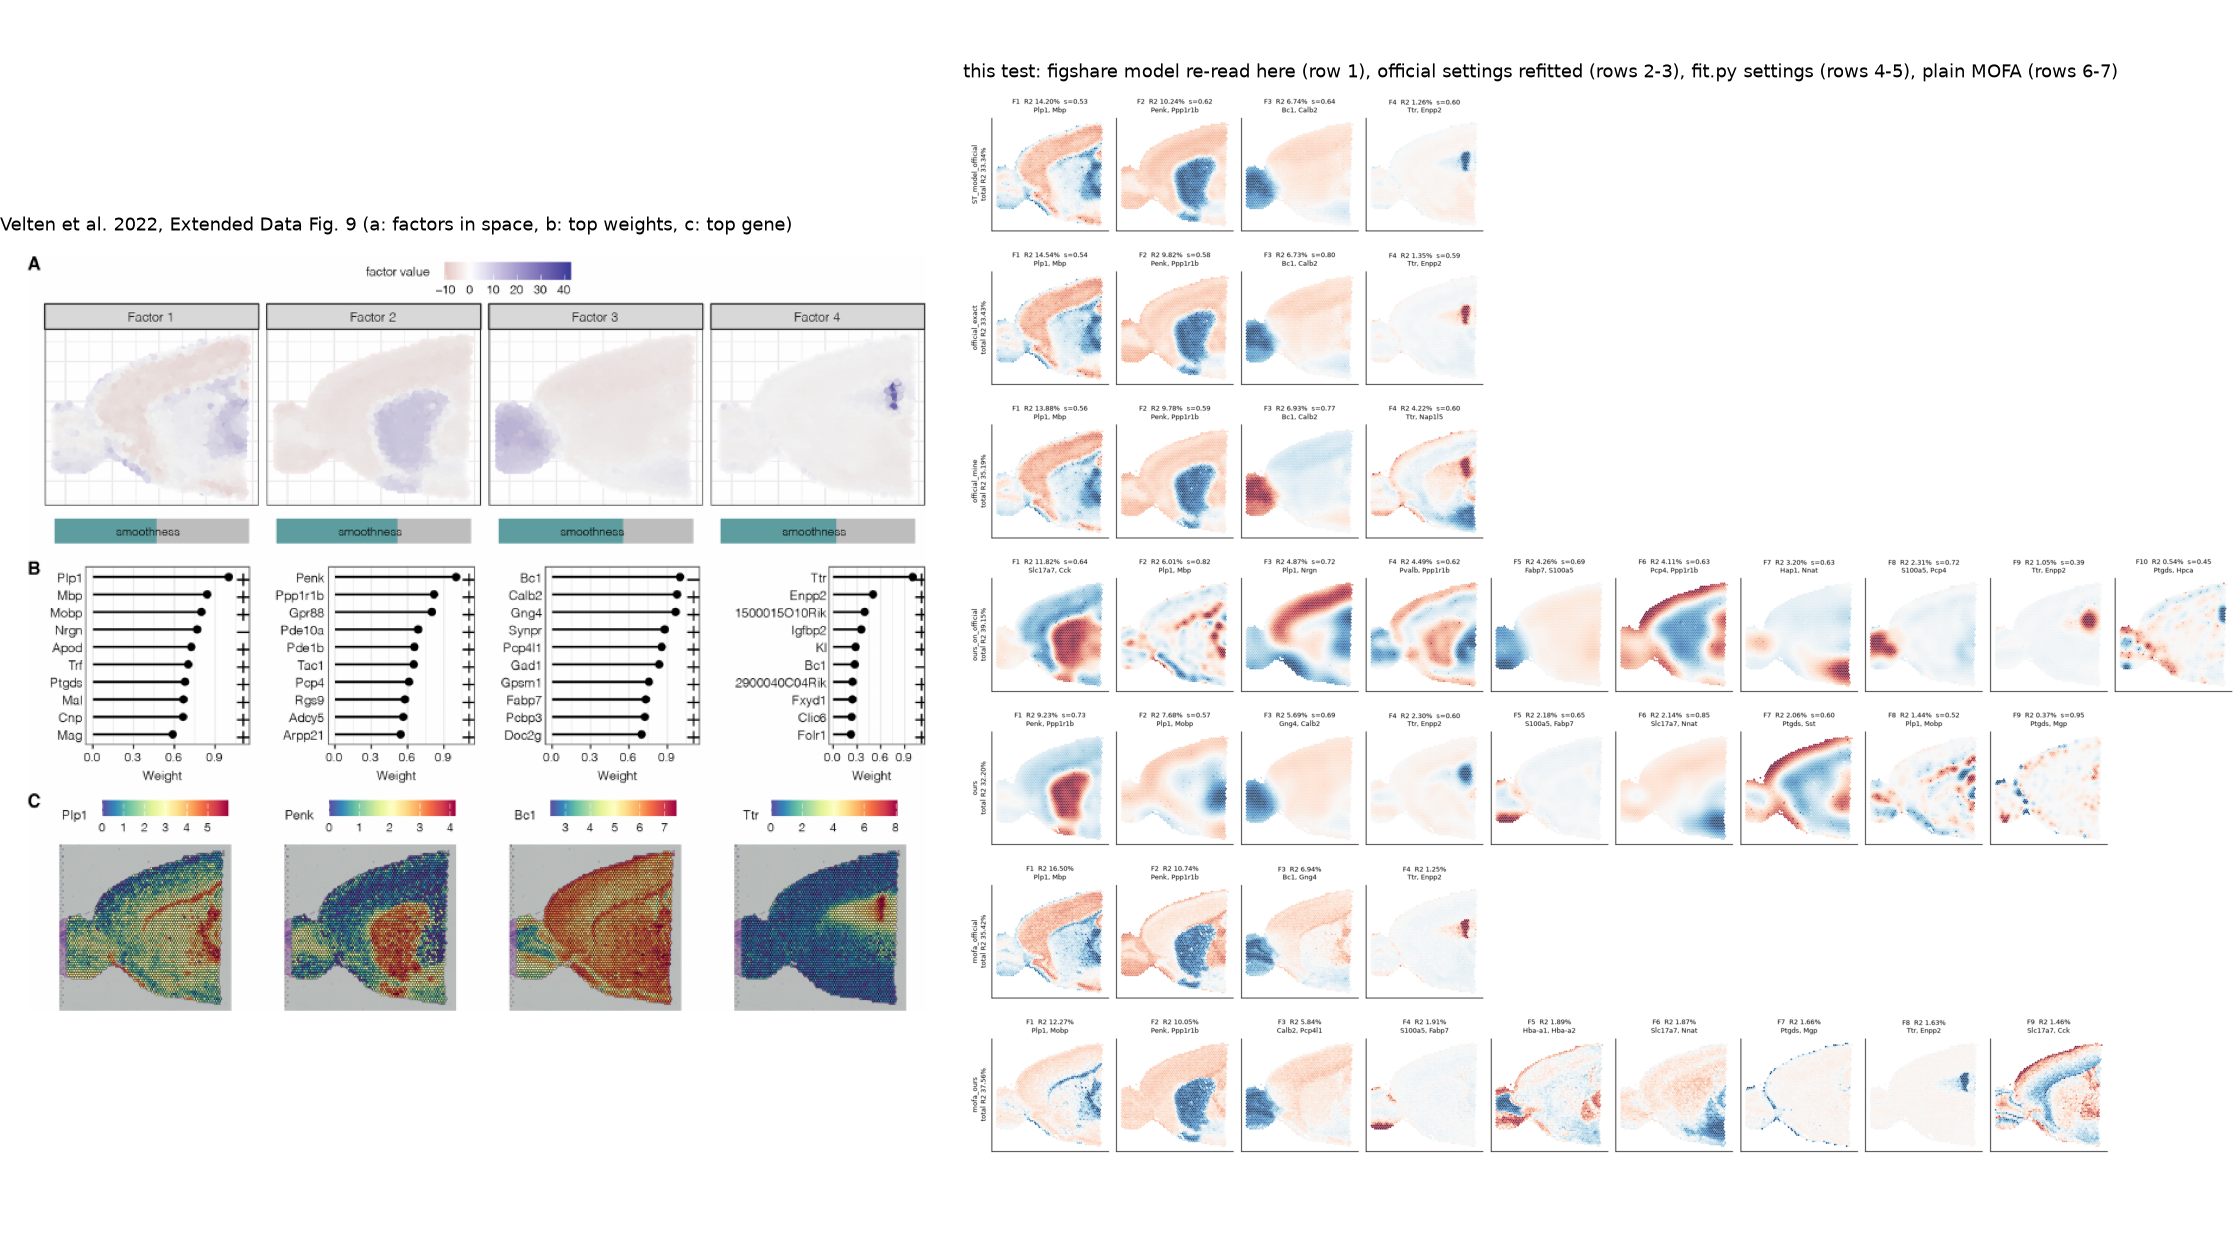

In [8]:
display(Image('sanity/figures/side_by_side_EDfig9.png'))

The paper's result reproduces (33.43 vs 33.34, factors matched at 0.99 to 1.00). Our pipeline finds the same four factors with the same marker genes. At K = 4 it explains 26.6%, about 7 points less than the paper- about 3 points come from the fit settings (fewer inducing points) and about 6 from the gene selection in `prep.py` (dispersion on log data instead of Seurat's vst on counts; with vst genes and the paper's settings, 35.2%). The gene choice lowers the PCA ceiling of the matrix itself (41 vs 47%), but the model reaches about 70% of the ceiling either way.

### 4b. The same tissue at the embryos' depth

Thin the Visium counts binomially to 1,200 per spot (the embryos' median) and refit. Same tissue, same genes, same code.


In [9]:
S.loc[['ours', 'ours_thin1200', 'official_thin1200', 'mofa_ours', 'mofa_thin1200'], ['K', 'n_active', 'r2_total', 'match_official']].rename(
    columns={'n_active': 'active', 'r2_total': 'R2 (%)', 'match_official': 'best match to paper factors'})

,K,active,R2 (%),best match to paper factors
name,,,,
ours,12.0,9,32.20,"{'F1': ('F2', 0.73), 'F2': ('F1', 0.96), 'F3': ('F3', 0.99), 'F4': ('F4', 0.84)}"
ours_thin1200,12.0,7,7.40,"{'F1': ('F1', 0.79), 'F2': ('F2', 0.96), 'F3': ('F3', 0.97), 'F4': ('F4', 0.85)}"
official_thin1200,4.0,4,6.76,"{'F1': ('F1', 0.84), 'F2': ('F2', 0.98), 'F3': ('F3', 0.98), 'F4': ('F4', 0.55)}"
mofa_ours,12.0,9,37.56,"{'F1': ('F1', 0.76), 'F2': ('F2', 0.97), 'F3': ('F3', 0.97), 'F4': ('F8', 0.94)}"
mofa_thin1200,12.0,11,10.34,"{'F1': ('F1', 0.77), 'F2': ('F2', 0.94), 'F3': ('F4', 0.91), 'F4': ('F7', 0.88)}"


In [10]:
pd.read_csv('sanity/tables/pca_ceiling.csv').set_index('variant').loc[['official', 'ours', 'ours_thin1200'], ['zeros', 'pc4', 'pc12']]

,zeros,pc4,pc12
variant,,,
official,0.633,37.58,47.38
ours,0.735,32.66,41.23
ours_thin1200,0.956,9.39,13.71


R2 falls from 32 to 7% but the four factors survive (matched at 0.79 to 0.97). The embryos with the paper's gene selection give 4.5 / 7.2% (section 1)- so the same depth gives the same R2.

> **[fill in: one sentence on what this isolates, and why it is the control the argument rests on.]**

### 4c. The one line that changed a number

Every setting in `fit.py` was flipped one at a time toward the paper's (`sanity/tables/ablation.md`). All of them moved R2 by less than the seed-to-seed noise (0.3 points), except the number of factors and the inducing fraction. The only preprocessing line that mattered is the gene selection, which `paper_recipe.py` fixes.


## 5. MOFA versus MEFISTO

MEFISTO adds a Gaussian-process prior over the coordinates: each factor is a smooth function of position plus noise, and the model learns per factor how much of its variance is smooth. The prior is a regulariser, so by construction MEFISTO fits less of the per-cell variation. Worth noting the paper never claims a higher R2 than MOFA, and on its own Visium data MOFA also wins (37.6 vs 32.2%).

Held-out tests (`heldout.py`, 1,000 cells per embryo, three masking seeds): A hides 10% of the entries of every cell and scores the reconstruction. B removes 10% of the cells entirely and MEFISTO predicts them from their coordinates alone- plain MOFA has no way to do this, so the baselines are the gene mean and the 10 nearest observed cells.


In [11]:
H = pd.read_csv('heldout_summary.csv')
H.pivot_table(index=['test', 'model'], columns='embryo', values=['r', 'mse']).round(3)

mse                   r          
embryo                   E8.0_rep1 E8.0_rep2 E8.0_rep1 E8.0_rep2
test model                                                      
A    MEFISTO                 0.195     0.198     0.434     0.474
     MOFA                    0.191     0.192     0.454     0.497
     gene mean               0.199     0.204     0.414     0.447
B    MEFISTO                 0.249     0.258     0.125     0.159
     gene mean               0.252     0.264     0.096     0.009
     kNN in space (k=10)     0.264     0.273     0.083     0.113

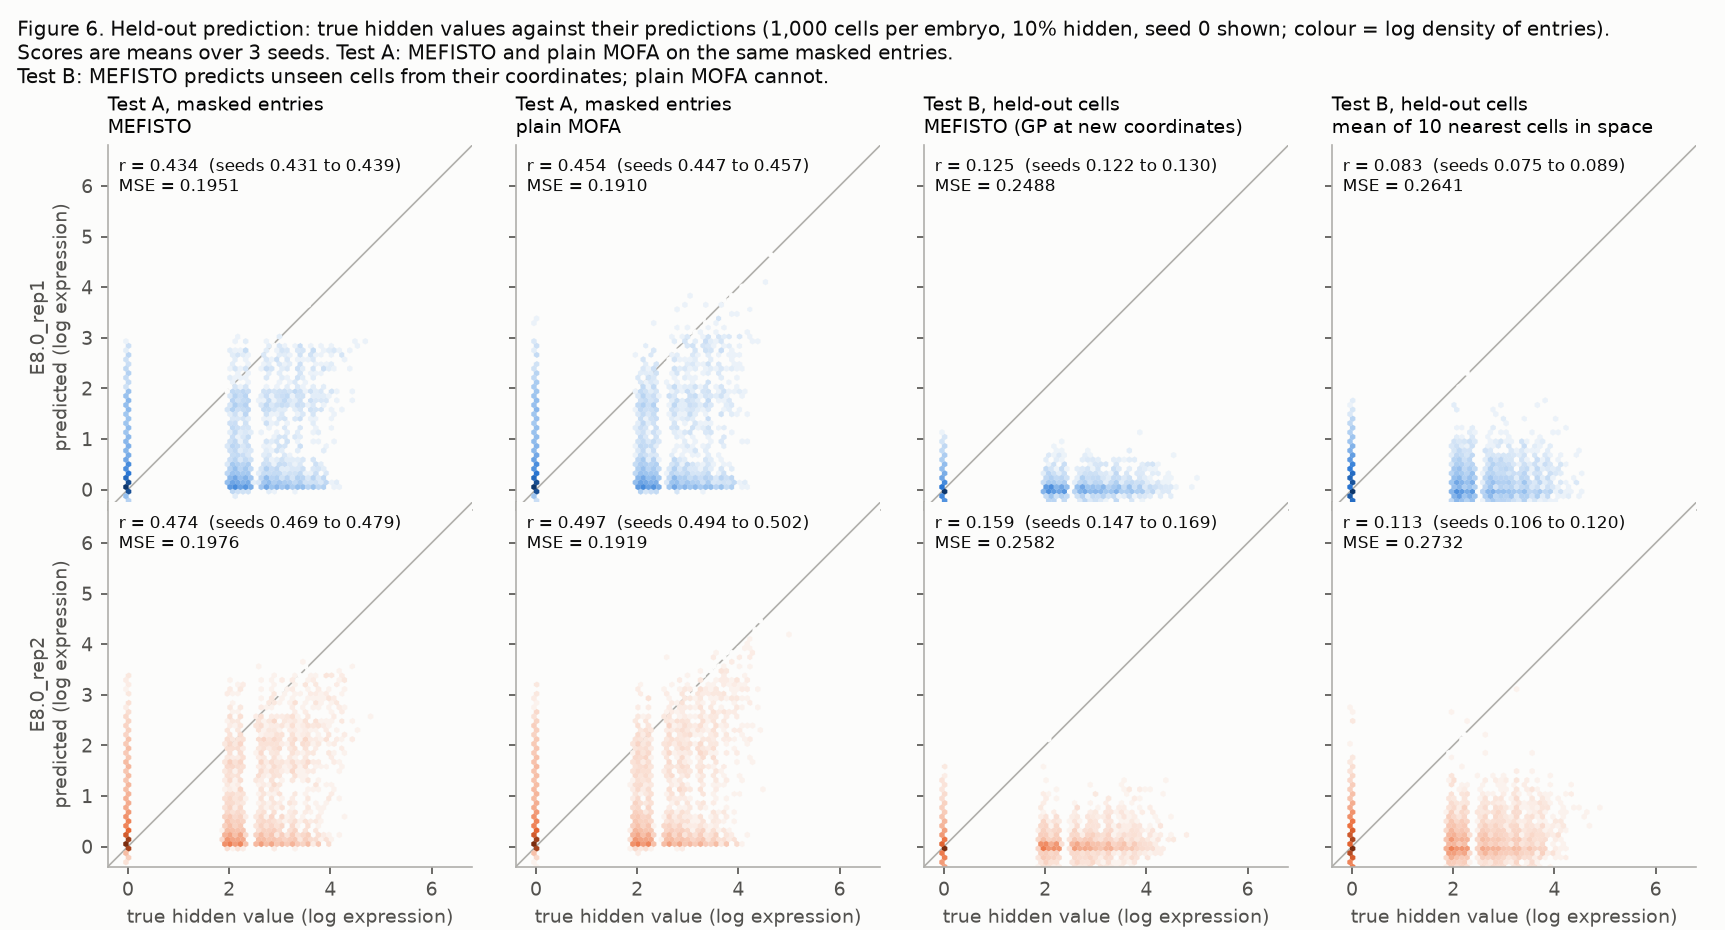

In [12]:
display(Image('figures/fig6_heldout.png'))

In [13]:
res = compare.classify_and_cluster({'MEFISTO': M['MEFISTO (presented)'], 'MOFA': M['MOFA (presented)']})
res['classifier'].round(3)

factors  classes  balanced accuracy  macro F1  baseline balanced accuracy  baseline macro F1
model   target                                                                                                  
MEFISTO germ layer        7        3              0.709     0.715                       0.333              0.206
        cell type         7       17              0.374     0.364                       0.059              0.017
MOFA    germ layer       12        3              0.859     0.862                       0.333              0.206
        cell type        12       17              0.457     0.450                       0.059              0.017

> **[fill in: the reading. MOFA wins on reconstructing observed cells, but only by a small margin; MEFISTO is the only one that can predict
> unseen positions and it beats the spatial baselines there. Why the gap is wider on the embryos than on Visium (ratio 0.4 vs 0.86):
> at low depth most per-cell variation is not smooth in space, and MEFISTO declines to fit it- it also switched off 5 of 12 factors.]**

## 6. What this means for the lab's data

> **[fill in: when per-entry variance explained is uninformative (counts per observation), what to report
> instead, and what MEFISTO is for (smoothness, sharedness across samples, prediction at unmeasured positions) vs what MOFA is
> for (reconstruction, denoising).]**
